<a href="https://colab.research.google.com/github/ituvtu/aerial-vehicle-detector/blob/main/notebooks/01_auto_label_yoloe26x.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 1: Automated Vehicle Labeling with YOLOE-26x (`01_auto_label_yoloe26x.ipynb`)

**Призначення ноутбука (Rule 2 & Rule 4):**
1. Клонує репозиторій із GitHub та підвантажує нарізані кадри `images_bundle.zip` (з Hugging Face без API-ключів або з Google Drive).
2. Запускає open-vocabulary детектор **`YOLOE-26x`** у комбінованому режимі (`Full-Frame 1280px` + `2x2 Tiling 1024px` + `NMS`) через `scripts/02_auto_label.py`.
3. Проводить первинний оптичний аудит дистанцій (`0–200 m` vs `200–400 m`) через `scripts/03_audit_labels.py`.
4. Візуалізує приклади розмічених кадрів та вивантажує архів міток (`labels_raw_and_init.zip`, ~40 КБ) на локальний ПК для ручної верифікації людиною.

In [1]:
# === 1. CLONE REPO & CHECK GPU ===
from pathlib import Path
import torch

# Public GitHub repository of this project:
GITHUB_REPO_URL = "https://github.com/ituvtu/aerial-vehicle-detector.git"
REPO_DIR = Path("/content/aerial-vehicle-detector")

if not REPO_DIR.exists():
    !git clone {GITHUB_REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull --ff-only

%cd {REPO_DIR}
!pip install -q "ultralytics>=8.4.0" "git+https://github.com/ultralytics/CLIP.git"

print(f"PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")

Cloning into '/content/aerial-vehicle-detector'...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (71/71), done.
remote: Compressing objects: 100% (50/50), done.
remote: Total 71 (delta 21), reused 68 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (71/71), 211.14 KiB | 1.17 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/aerial-vehicle-detector
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
PyTorch: 2.11.0+cu130 | CUDA available: True
GPU Device: Tesla T4


In [2]:
# === 2. DOWNLOAD & EXTRACT FRAMES (HUGGING FACE / GOOGLE DRIVE) ===
import yaml
from src.manifest_manager import ensure_images_available, sync_manifest_splits

with open("configs/project_config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

# Якщо ти завантажив images_bundle.zip на Hugging Face і вписав URL у project_config.yaml,
# функція нижче скачає і розпакує його автоматично за 2 секунди.
# Альтернатива: якщо файл на твоєму Google Drive, розкоментуй 3 рядки нижче:
# from google.colab import drive
# drive.mount('/content/drive')
# !cp /content/drive/MyDrive/images_bundle.zip data/images_bundle.zip

ensure_images_available(
    manifest_path=cfg["paths"]["manifest_path"],
    images_dir=cfg["paths"]["images_dir"],
    bundle_zip_path=cfg["paths"]["images_bundle_zip"],
    bundle_url=cfg.get("remote_data", {}).get("images_bundle_url"),
)
counts = sync_manifest_splits()
print("Кадри розпаковано. Розподіл по сплітах:", counts)

[Auto-Fetch] Downloading https://huggingface.co/datasets/ituvtu/aerial-vehicle-detector-data/resolve/main/images_bundle.zip -> data/images_bundle.zip ...
[Auto-Fetch] Extracting 'data/images_bundle.zip' into 'data/images' ...
Кадри розпаковано. Розподіл по сплітах: {'train': 73, 'val': 18, 'test': 64}


In [3]:
# === 3. RUN AUTO-LABELING YOLOE-26x & DISTANCE AUDIT ===
!python scripts/02_auto_label.py && python scripts/03_audit_labels.py

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Auto-labeling (yoloe-26x-seg.pt): 100% 155/155 [00:56<00:00,  2.75frame/s]

Auto-labeling complete!
  Frames processed : 155
  Total boxes found: 3156 (avg 20.4 vehicles/frame)
  Raw labels saved : /content/aerial-vehicle-detector/data/labels_raw
  Working labels   : /content/aerial-vehicle-detector/data/labels

RULE 2: HUMAN LABEL AUDIT SUMMARY (labels_raw vs labels)
  Raw boxes (YOLOE-26x) : 3156
  Final boxes (Human)   : 3156
  ----------------------------------------
  Unchanged (IoU>=0.98) : 3156
  Fixed / Adjusted      : 0
  Removed (False Pos)   : 0
  Added (Missed / FN)   : 0

--------------------------------------------------------------------------
RULE 4: VEHICLE COUNT BY DISTANCE BAND AN

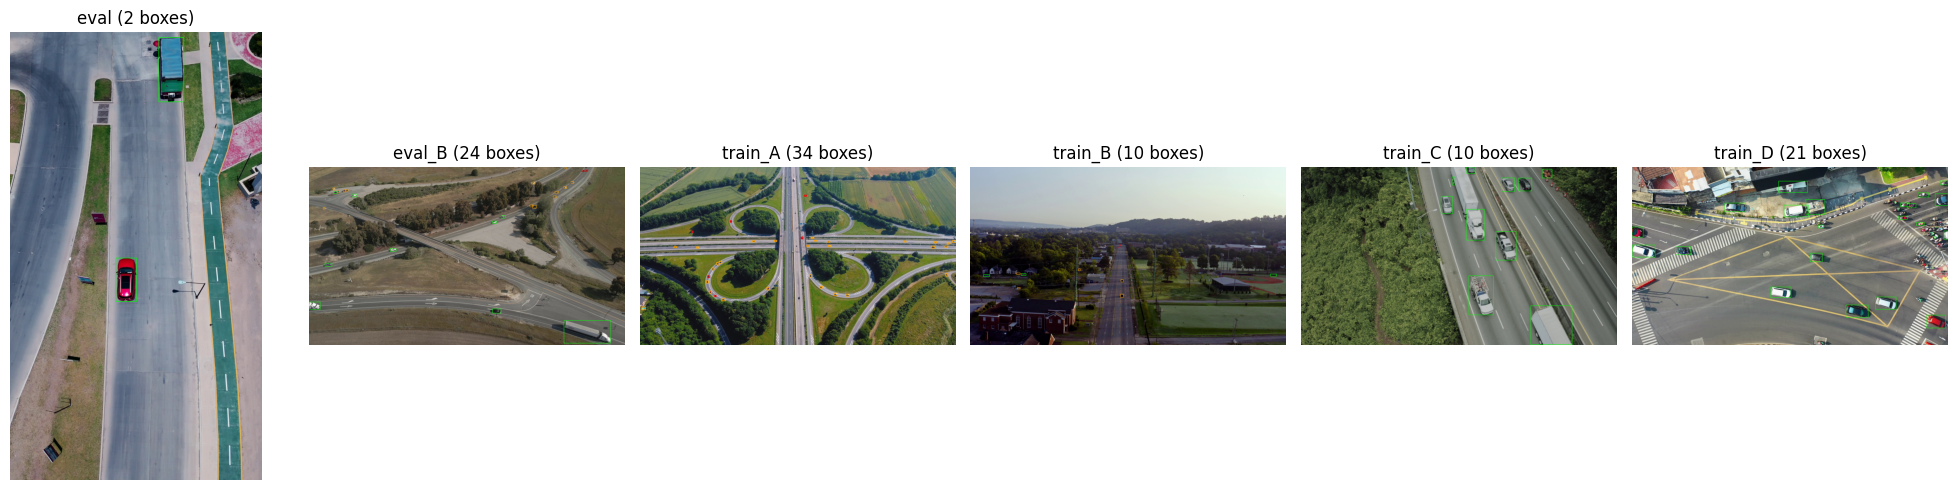

In [4]:
# === 4. QUICK VISUALIZATION OF LABELS (0-200m vs 200-400m) ===
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from src.manifest_manager import get_active_frames, parse_yolo_label_file
from src.optics import CameraOpticsConfig, estimate_distance_m_from_yolo_norm, assign_distance_band

df = get_active_frames()
sample_rows = df.groupby("role").first().reset_index()

fig, axes = plt.subplots(1, len(sample_rows), figsize=(20, 5))
optics_cfg = CameraOpticsConfig()

for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    img = cv2.imread(row["image_path"])
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h_px, w_px = img_rgb.shape[:2]
    boxes = parse_yolo_label_file(Path("data/labels_raw") / f"{row['frame_id']}.txt")
    for xc, yc, w, h in boxes:
        dist = estimate_distance_m_from_yolo_norm(w, h, w_px, h_px, optics_cfg)
        band = assign_distance_band(dist, optics_cfg)
        color = (0, 255, 0) if band == "0-200m" else ((255, 165, 0) if band == "200-400m" else (255, 0, 0))
        x1, y1 = int((xc - w / 2) * w_px), int((yc - h / 2) * h_px)
        x2, y2 = int((xc + w / 2) * w_px), int((yc + h / 2) * h_px)
        cv2.rectangle(img_rgb, (x1, y1), (x2, y2), color, 4)
    ax.imshow(img_rgb)
    ax.set_title(f"{row['role']} ({len(boxes)} boxes)")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
# === 5. PACK SIGNED RAW ARTIFACT & DOWNLOAD TO LOCAL PC ===
!python scripts/cvat_cli_pipeline.py pack-raw-artifact
from pathlib import Path
from google.colab import files
artifacts = sorted(Path("artifacts").glob("raw_autolabel_*.zip"))
if not artifacts:
    raise FileNotFoundError("No signed raw artifact found in artifacts/")
bundle_path = artifacts[-1]
print(f"Downloading signed artifact: {bundle_path}")
files.download(str(bundle_path))


[Artifact] Packed raw bundle: /content/aerial-vehicle-detector/artifacts/raw_autolabel_20261104T182405Z_8630536e.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>